In [88]:
import numpy as np
import pandas as pd
import sounddevice as sd

from pathlib import Path
from scipy.io.wavfile import write

In [89]:
# ===============================
# Sampling Parameters
# ===============================

FS = 44100              # Sampling rate (Hz)
DURATION = 1          # seconds

# ===============================
# Stimulus Parameters
# ===============================

BASE_FREQ = 80          # Hz
TONE_COUNT = 3

IFI_LEVELS = [50, 100, 150]

ATTACK_TIMES = [100, 250, 400]      # milliseconds

AM_DEPTHS = [0.3, 0.6, 0.9]

AM_FREQ = 10                      # Hz

TARGET_RMS = 0.20

In [90]:
def play(signal):

    signal = signal / np.max(np.abs(signal))

    sd.play(signal, FS)

    sd.wait()

In [91]:
def save_wav(signal, filename):

    signal = signal / np.max(np.abs(signal))

    write(
        filename,
        FS,
        np.int16(signal * 32767)
    )

In [92]:
def rms_normalize(signal, target_rms=TARGET_RMS):

    rms = np.sqrt(np.mean(signal**2))

    if rms > 0:

        signal = signal * (target_rms / rms)

    return signal

In [93]:
def generate_complex_tone(
    ifi,
    duration=DURATION,
    base_freq=BASE_FREQ
):
    
    t = np.linspace(
        0,
        duration,
        int(FS * duration),
        endpoint=False
    )

    freqs = [
        base_freq,
        base_freq + ifi,
        base_freq + 2*ifi
    ]

    signal = np.zeros_like(t)

    for freq in freqs:

        signal += np.sin(
            2*np.pi*freq*t
        )

    signal = rms_normalize(signal)

    return signal, freqs

In [94]:
def apply_attack(
    signal,
    attack_ms
):

    attack_samples = int(
        attack_ms / 1000 * FS
    )

    envelope = np.ones(len(signal))

    envelope[:attack_samples] = np.linspace(
        0,
        1,
        attack_samples
    )

    signal = signal * envelope

    signal = rms_normalize(signal)

    return signal

In [95]:
def apply_am(
    signal,
    depth,
    am_freq=AM_FREQ
):

    t = np.linspace(
        0,
        len(signal)/FS,
        len(signal),
        endpoint=False
    )

    envelope = (

        1 +

        depth *

        np.sin(
            2*np.pi*am_freq*t
        )

    )

    signal = signal * envelope

    signal = rms_normalize(signal)

    return signal

In [96]:
def generate_stimulus(
    ifi,
    attack,
    am_depth
):

    signal, freqs = generate_complex_tone(
        ifi
    )

    signal = apply_attack(
        signal,
        attack
    )

    signal = apply_am(
        signal,
        am_depth
    )

    signal = rms_normalize(signal)

    return signal, freqs

In [97]:
signal, freqs = generate_stimulus(
    ifi=100,
    attack=80,
    am_depth=0.6
)

print(freqs)

play(signal)

[80, 180, 280]


In [98]:
# ======================================
# Output Folder
# ======================================

output_dir = Path("../Stimuli/final_27")

output_dir.mkdir(
    parents=True,
    exist_ok=True
)

In [99]:
stimulus_table = []

stim_id = 1

for attack in ATTACK_TIMES:

    for ifi in IFI_LEVELS:

        for am in AM_DEPTHS:

            signal, freqs = generate_stimulus(
                ifi=ifi,
                attack=attack,
                am_depth=am
            )

            filename = (
                f"S{stim_id:02d}"
                f"_ATT{attack}"
                f"_IFI{ifi}"
                f"_AM{int(am*100)}.wav"
            )

            save_wav(
                signal,
                output_dir / filename
            )

            stimulus_table.append(
                [
                    stim_id,
                    attack,
                    ifi,
                    freqs,
                    am
                ]
            )

            stim_id += 1

In [100]:
df = pd.DataFrame(

    stimulus_table,

    columns=[

        "ID",

        "AttackTime_ms",

        "IFI_Hz",

        "Frequencies",

        "AM_Depth"

    ]

)

df

,ID,AttackTime_ms,IFI_Hz,Frequencies,AM_Depth
0,1,100,50,"[80, 130, 180]",0.3
1,2,100,50,"[80, 130, 180]",0.6
2,3,100,50,"[80, 130, 180]",0.9
3,4,100,100,"[80, 180, 280]",0.3
4,5,100,100,"[80, 180, 280]",0.6
5,6,100,100,"[80, 180, 280]",0.9
6,7,100,150,"[80, 230, 380]",0.3
7,8,100,150,"[80, 230, 380]",0.6
8,9,100,150,"[80, 230, 380]",0.9
9,10,250,50,"[80, 130, 180]",0.3


In [101]:
df.to_csv(

    output_dir / "stimulus_table.csv",

    index=False

)

print("Stimulus table saved!")

Stimulus table saved!


In [102]:
files = sorted(output_dir.glob("*.wav"))

print(f"Total WAV files: {len(files)}")

for file in files[:5]:
    print(file.name)

Total WAV files: 27
S01_ATT100_IFI50_AM30.wav
S02_ATT100_IFI50_AM60.wav
S03_ATT100_IFI50_AM90.wav
S04_ATT100_IFI100_AM30.wav
S05_ATT100_IFI100_AM60.wav


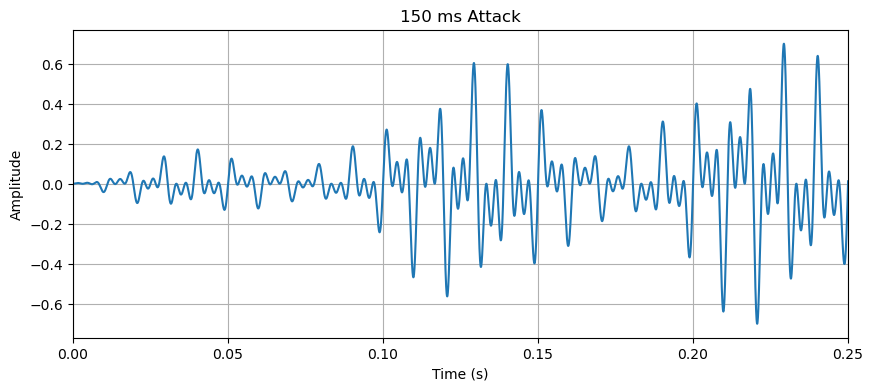

In [103]:
import matplotlib.pyplot as plt

signal, _ = generate_stimulus(
    ifi=100,
    attack=150,
    am_depth=0.6
)

t = np.arange(len(signal)) / FS

plt.figure(figsize=(10,4))
plt.plot(t, signal)
plt.xlim(0,0.25)
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title("150 ms Attack")
plt.grid(True)
plt.show()

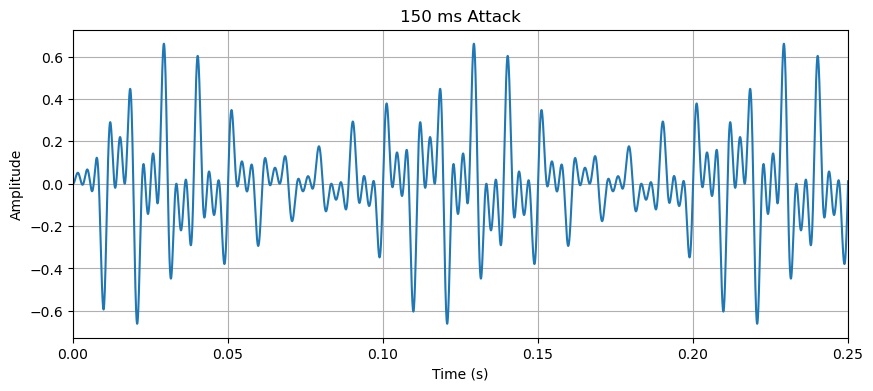

In [104]:
import matplotlib.pyplot as plt

signal, _ = generate_stimulus(
    ifi=100,
    attack=10,
    am_depth=0.6
)

t = np.arange(len(signal)) / FS

plt.figure(figsize=(10,4))
plt.plot(t, signal)
plt.xlim(0,0.25)
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title("150 ms Attack")
plt.grid(True)
plt.show()

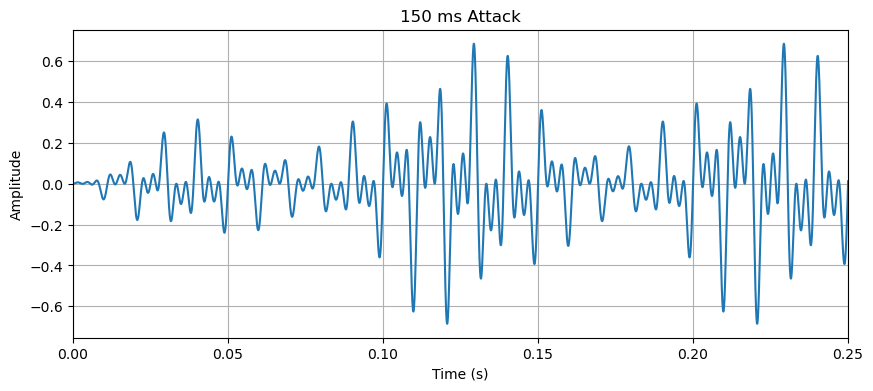

In [105]:
import matplotlib.pyplot as plt

signal, _ = generate_stimulus(
    ifi=100,
    attack=80,
    am_depth=0.6
)

t = np.arange(len(signal)) / FS

plt.figure(figsize=(10,4))
plt.plot(t, signal)
plt.xlim(0,0.25)
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title("150 ms Attack")
plt.grid(True)
plt.show()

In [106]:
TEST_ATTACKS = [50, 150, 300]

ifi = 100
am = 0.6

for attack in TEST_ATTACKS:

    print(f"\nPlaying Attack = {attack} ms")

    signal, _ = generate_stimulus(
        ifi=ifi,
        attack=attack,
        am_depth=am
    )

    play(signal)


Playing Attack = 50 ms

Playing Attack = 150 ms

Playing Attack = 300 ms


In [107]:
TEST_ATTACKS = [100, 250, 400]

ifi = 100
am = 0.6

for attack in TEST_ATTACKS:

    print(f"\nPlaying Attack = {attack} ms")

    signal, _ = generate_stimulus(
        ifi=ifi,
        attack=attack,
        am_depth=am
    )

    play(signal)


Playing Attack = 100 ms

Playing Attack = 250 ms

Playing Attack = 400 ms


In [108]:
TEST_ATTACKS = [100, 300, 500]

ifi = 100
am = 0.6

for attack in TEST_ATTACKS:

    print(f"\nPlaying Attack = {attack} ms")

    signal, _ = generate_stimulus(
        ifi=ifi,
        attack=attack,
        am_depth=am
    )

    play(signal)


Playing Attack = 100 ms

Playing Attack = 300 ms

Playing Attack = 500 ms


In [109]:
TEST_ATTACKS = [150, 350, 550]

ifi = 100
am = 0.6

for attack in TEST_ATTACKS:

    print(f"\nPlaying Attack = {attack} ms")

    signal, _ = generate_stimulus(
        ifi=ifi,
        attack=attack,
        am_depth=am
    )

    play(signal)


Playing Attack = 150 ms

Playing Attack = 350 ms

Playing Attack = 550 ms


In [110]:
def compare_attacks(att1, att2, ifi=100, am=0.6):

    sig1, _ = generate_stimulus(
        ifi=ifi,
        attack=att1,
        am_depth=am
    )

    sig2, _ = generate_stimulus(
        ifi=ifi,
        attack=att2,
        am_depth=am
    )

    print(f"\nAttack {att1} ms")
    play(sig1)

    print("-----")

    print(f"Attack {att2} ms")
    play(sig2)

compare_attacks(250, 400)



Attack 250 ms
-----
Attack 400 ms
